# CS3807 – Deep Learning Laboratory — Experiment 3
## Implementation of Convolutional Neural Networks (CNNs) for Image Classification

**B.Tech Artificial Intelligence & Data Science | Semester V | AY 2026–27**

**Objective:** Understand the working principle of Convolutional Neural Networks by
implementing convolution, pooling, feature-map visualization, and image classification
using TensorFlow/Keras, on the CIFAR-10 dataset.

---

## How to Run This Notebook in Google Colab

1. Open [Google Colab](https://colab.research.google.com) and upload this notebook
   (`File -> Upload notebook`), or open it directly from Drive/GitHub.
2. Set the runtime to GPU: `Runtime -> Change runtime type -> Hardware accelerator -> GPU`.
3. Run all cells top to bottom (`Runtime -> Run all`). No extra installs are required —
   TensorFlow, scikit-learn, scikit-image, SciPy, pandas, and Matplotlib are preinstalled
   on Colab.
4. Figures are saved as 600 DPI `.eps` files under `figures/`, and trained models under
   `models/`, in the Colab session's local storage. To keep them permanently, mount
   Google Drive **before** running the setup cell:
   ```python
   from google.colab import drive
   drive.mount('/content/drive')
   ```
   then change `CONFIG["fig_dir"]` and `CONFIG["model_dir"]` below to paths under
   `/content/drive/MyDrive/...`.
5. **Approximate runtime:** five CNN variants × 20 epochs each ≈ 15–25 minutes on a
   Colab T4 GPU. On CPU-only runtime this can take well over an hour — GPU is strongly
   recommended.
6. **Times New Roman font:** Colab's Linux runtime does not ship this font by default.
   The styling cell below auto-detects this and falls back to a serif font so every cell
   still runs. To use the exact font, either upload a `.ttf` of Times New Roman and
   register it with `matplotlib.font_manager.fontManager.addfont(...)` before running the
   styling cell, or install a close metric-compatible serif via
   `!apt-get -qq install -y fonts-liberation`.
7. Re-running the notebook end-to-end reproduces the same train/validation split and
   model initializations (a fixed seed is set in the configuration cell).

---

## Notebook Structure
- **Part A** — Convolution fundamentals: classical kernels (Manual Section 3.1)
- **Part B** — Worked numerical examples (Manual Sections 4–6)
- **Part C** — Task 1: CIFAR-10 loading and exploration
- **Part D** — Tasks 2 & 3: kernel-size, stride, and padding studies
- **Part E** — CNN architecture definition
- **Part F** — Task 4: feature-map and filter visualization (untrained, conv1 & conv2)
- **Part G** — Shared training/evaluation harness
- **Part H** — Task 6: main CNN training
- **Part I** — Task 5: Max- vs. Average-Pooling ablation
- **Part J** — Additional Exercise 3: ReLU vs. Sigmoid ablation
- **Part K** — Additional Exercise 5: 16- vs. 64-filter ablation
- **Part L** — Additional Exercises 1 & 2: formula-based calculations
- **Part M** — Task 7: full evaluation of the main model
- **Part N** — Results summary and model export

## Part 0 — Environment Setup, Configuration, and Reproducibility

In [1]:
"""
Imports and global experiment configuration. All hyperparameters that are
reused across the notebook (seed, epochs, batch size, image shape, figure
export settings) live in a single CONFIG dict to avoid magic numbers and to
keep re-running the notebook on a different dataset a matter of editing one
place.
"""
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from scipy.signal import convolve2d, correlate2d
from skimage import data, img_as_float

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

CONFIG = {
    "seed": 42,
    "epochs": 20,
    "batch_size": 32,
    "img_shape": (32, 32, 3),
    "num_classes": 10,
    "val_fraction": 0.1,
    "learning_rate": 1e-3,
    "fig_dir": "figures",
    "model_dir": "models",
    "dpi": 600,
    "fig_format": "eps",
}

os.makedirs(CONFIG["fig_dir"], exist_ok=True)
os.makedirs(CONFIG["model_dir"], exist_ok=True)


def set_global_seed(seed: int) -> None:
    """Seed Python, NumPy, and TensorFlow RNGs for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_global_seed(CONFIG["seed"])

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
"""
Configure global Matplotlib styling: Times New Roman font family (13-15pt),
bold axis titles/labels, and bold figure titles, per the lab's formatting
guidelines. Falls back to the nearest available serif font if Times New
Roman is not installed on the runtime, so the notebook still executes.
"""
def configure_plot_style(preferred_font: str = "Times New Roman", size: int = 13) -> None:
    """Apply the notebook-wide Matplotlib rcParams style."""
    available = {f.name for f in fm.fontManager.ttflist}
    family = preferred_font if preferred_font in available else "serif"
    if family != preferred_font:
        print(f"'{preferred_font}' not found on this system — falling back to '{family}'. "
              f"See the setup instructions above to install the exact font.")
    plt.rcParams.update({
        "font.family": family,
        "font.size": size,
        "axes.titlesize": size + 2,
        "axes.titleweight": "bold",
        "axes.labelsize": size + 1,
        "axes.labelweight": "bold",
        "xtick.labelsize": size,
        "ytick.labelsize": size,
        "legend.fontsize": size,
        "figure.titlesize": min(size + 2, 15),
        "figure.titleweight": "bold",
    })


configure_plot_style(size=13)

'Times New Roman' not found on this system — falling back to 'serif'. See the setup instructions above to install the exact font.


In [3]:
"""
Reusable helpers for enforcing bold tick/legend text (legend text weight has
no global rcParam, so it is set explicitly) and for exporting every figure
in the notebook as a 600 DPI EPS file, per the lab formatting guidelines.
"""
def bold_axes(ax) -> None:
    """Force bold font weight on an axis's tick labels and legend text."""
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontweight("bold")


def save_figure(fig, name: str, rasterize: bool = True) -> str:
    """Apply bold axis/legend styling, save `fig` as a 600 DPI EPS file under
    CONFIG['fig_dir'], display it inline, and return the saved path."""
    for ax in fig.get_axes():
        bold_axes(ax)
        if rasterize:
            for artist in ax.get_images():
                artist.set_rasterized(True)
    path = os.path.join(CONFIG["fig_dir"], f"{name}.{CONFIG['fig_format']}")
    fig.savefig(path, format=CONFIG["fig_format"], dpi=CONFIG["dpi"], bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")
    return path

In [4]:
"""
Closed-form utilities for CNN output-size and parameter-count arithmetic.
Used throughout the notebook to cross-check values produced by actual Keras
layers against the formulas in Section 3 of the lab manual.
"""
def conv_output_size(n: int, f: int, p: int, s: int) -> int:
    """Output spatial size for a square input of size n, filter size f,
    padding p (pixels per side), and stride s:  floor((N - F + 2P)/S) + 1."""
    return (n - f + 2 * p) // s + 1


def conv_param_count(num_filters: int, kernel_size: int, in_channels: int, bias: bool = True) -> int:
    """Trainable parameter count for a Conv2D layer:
    (kernel_size^2 * in_channels + bias) * num_filters."""
    per_filter = kernel_size * kernel_size * in_channels + (1 if bias else 0)
    return per_filter * num_filters

## Part A — Understanding the Convolution Operation (Manual Section 3.1)

Section 3.1 of the manual defines ten canonical convolution kernels used to extract
different visual characteristics from an image. This section applies each kernel to a
reference image so their effects are directly observable before the CNN itself is
introduced.

Reference image shape: (512, 512) | value range: [0, 1]


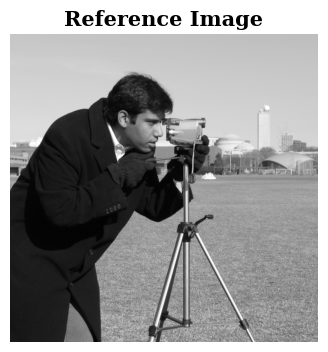

Saved: figures/01_reference_image.eps


'figures/01_reference_image.eps'

In [5]:
"""
Load a high-resolution grayscale reference image for the classical-kernel
demonstration. CIFAR-10 images (32x32) are too small to visibly show the
effect of blur/sharpen/emboss kernels, so a larger standard test image is
used here; CIFAR-10 itself is introduced separately in Part C.
"""
reference_image = img_as_float(data.camera())
print("Reference image shape:", reference_image.shape, "| value range: [0, 1]")

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(reference_image, cmap="gray")
ax.set_title("Reference Image")
ax.axis("off")
save_figure(fig, "01_reference_image")

In [6]:
"""
Define the ten canonical convolution kernels from Section 3.1 of the lab
manual as NumPy arrays.
"""
CLASSICAL_KERNELS = {
    "Identity": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float),
    "Sobel-X": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "Sobel-Y": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
    "Laplacian": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float),
    "Sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "Box Blur": np.ones((3, 3), dtype=float) / 9.0,
    "Gaussian Blur": np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16.0,
    "Emboss": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
    "Outline": np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=float),
    "Motion Blur": np.eye(5, dtype=float) / 5.0,
}

for name, k in CLASSICAL_KERNELS.items():
    print(f"{name:15s} shape={str(k.shape):8s} sum={k.sum():.3f}")

Identity        shape=(3, 3)   sum=1.000
Sobel-X         shape=(3, 3)   sum=0.000
Sobel-Y         shape=(3, 3)   sum=0.000
Laplacian       shape=(3, 3)   sum=0.000
Sharpen         shape=(3, 3)   sum=1.000
Box Blur        shape=(3, 3)   sum=1.000
Gaussian Blur   shape=(3, 3)   sum=1.000
Emboss          shape=(3, 3)   sum=1.000
Outline         shape=(3, 3)   sum=0.000
Motion Blur     shape=(5, 5)   sum=1.000


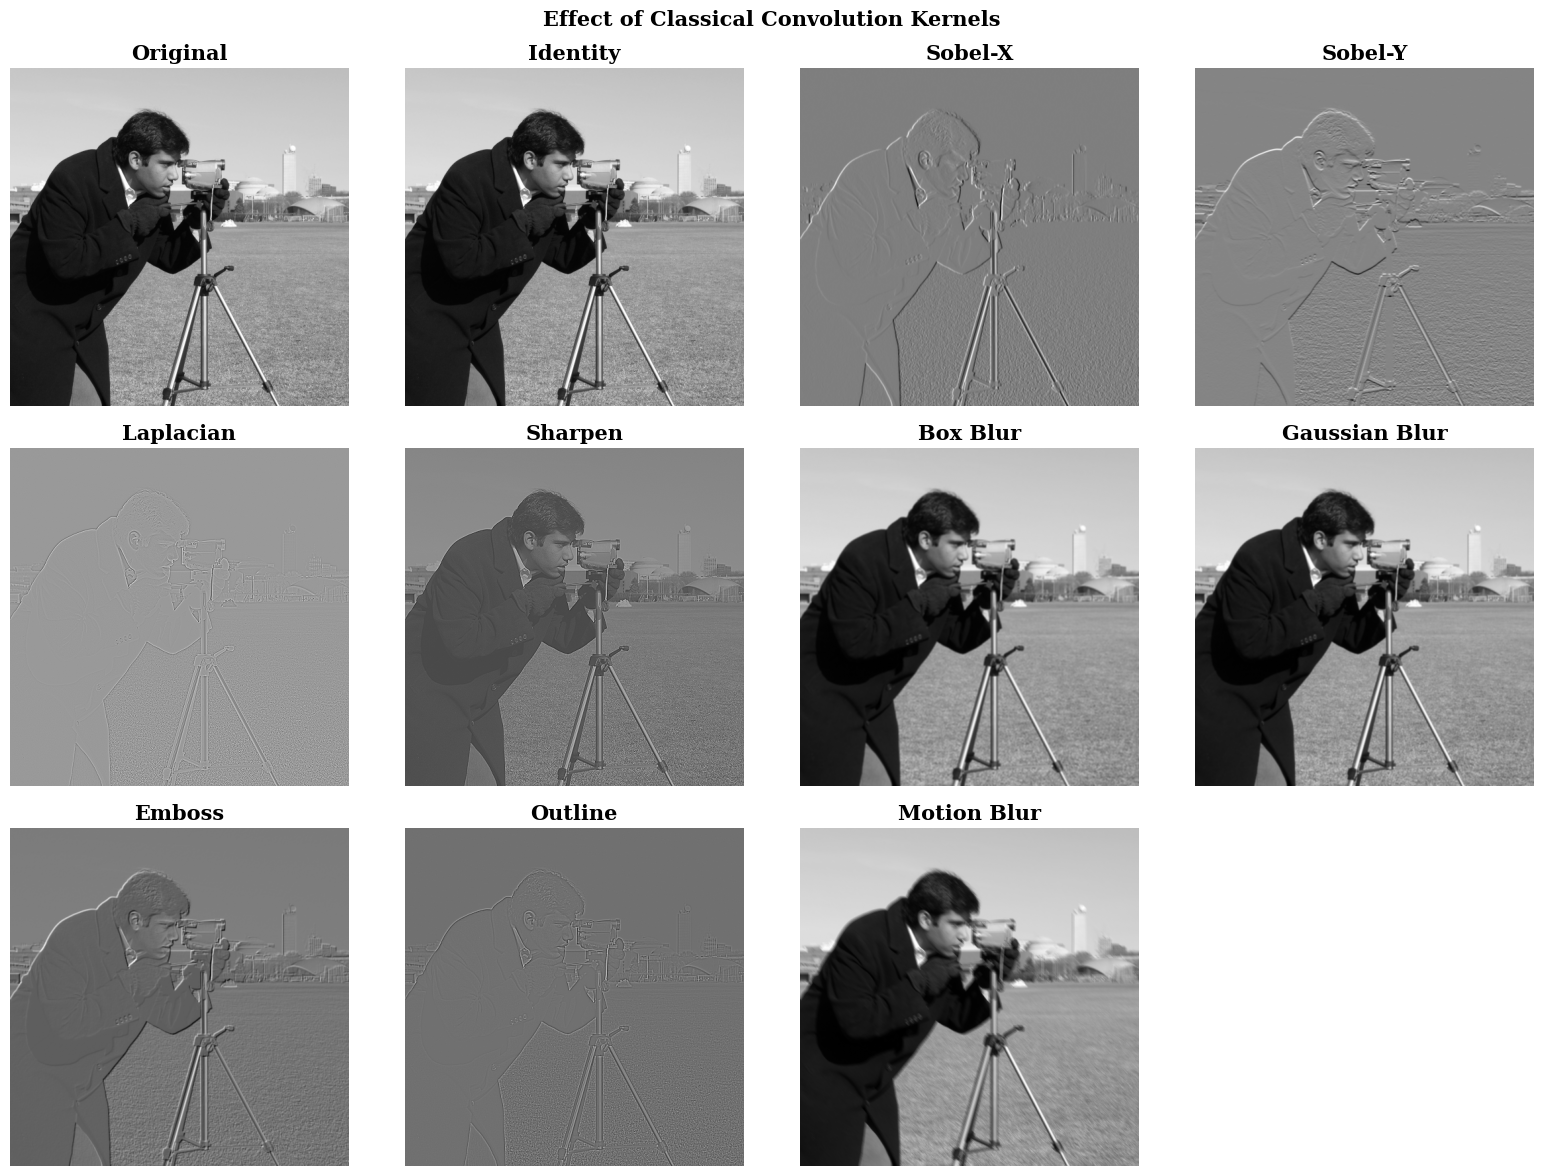

Saved: figures/02_classical_kernels_grid.eps


'figures/02_classical_kernels_grid.eps'

In [7]:
"""
Apply every classical kernel to the reference image via 2D convolution and
display all results in a single subplot grid (per formatting guideline:
club multiple plots into one figure).
"""
def apply_kernel(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Convolve a 2D image with a 2D kernel, same-size output, symmetric
    boundary padding."""
    return convolve2d(image, kernel, mode="same", boundary="symm")


kernel_outputs = {name: apply_kernel(reference_image, k) for name, k in CLASSICAL_KERNELS.items()}

n_panels = len(kernel_outputs) + 1
n_cols = 4
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

axes[0].imshow(reference_image, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for i, (name, out) in enumerate(kernel_outputs.items(), start=1):
    axes[i].imshow(out, cmap="gray")
    axes[i].set_title(name)
    axes[i].axis("off")

for j in range(n_panels, len(axes)):
    axes[j].axis("off")

fig.suptitle("Effect of Classical Convolution Kernels")
fig.tight_layout()
save_figure(fig, "02_classical_kernels_grid")

## Part B — Worked Numerical Examples (Manual Sections 4–6)

Small, hand-traceable examples that make the sliding-window mechanics of convolution,
max pooling, and parameter counting explicit, before scaling up to real images.

In [8]:
"""
Numerical Example 1 (Manual Section 4): manual convolution walkthrough. An
illustrative 5x5 input and a 3x3 kernel are convolved position by position
(stride 1, valid padding) to make the sliding-window mechanics explicit.
"""
demo_input = np.array([
    [1, 2, 3, 0, 1],
    [4, 5, 6, 1, 0],
    [7, 8, 9, 2, 1],
    [1, 0, 2, 3, 4],
    [0, 1, 2, 1, 0],
], dtype=float)

demo_kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
], dtype=float)


def convolve_step_by_step(image: np.ndarray, kernel: np.ndarray, stride: int = 1) -> np.ndarray:
    """Slide `kernel` over `image` (valid padding), printing every window's
    element-wise product-sum, and return the resulting feature map."""
    kh, kw = kernel.shape
    ih, iw = image.shape
    oh = (ih - kh) // stride + 1
    ow = (iw - kw) // stride + 1
    feature_map = np.zeros((oh, ow))
    position = 1
    for i in range(oh):
        for j in range(ow):
            window = image[i * stride:i * stride + kh, j * stride:j * stride + kw]
            value = np.sum(window * kernel)
            feature_map[i, j] = value
            print(f"Position {position:2d} -> rows[{i*stride}:{i*stride+kh}], "
                  f"cols[{j*stride}:{j*stride+kw}]  =>  output = {value:.1f}")
            position += 1
    return feature_map


demo_feature_map = convolve_step_by_step(demo_input, demo_kernel, stride=1)
print("\nResulting feature map:\n", demo_feature_map)

reference_check = correlate2d(demo_input, demo_kernel, mode="valid")
print("\nSciPy cross-check matches manual result:", np.allclose(demo_feature_map, reference_check))

Position  1 -> rows[0:3], cols[0:3]  =>  output = -6.0
Position  2 -> rows[0:3], cols[1:4]  =>  output = 12.0
Position  3 -> rows[0:3], cols[2:5]  =>  output = 16.0
Position  4 -> rows[1:4], cols[0:3]  =>  output = -5.0
Position  5 -> rows[1:4], cols[1:4]  =>  output = 7.0
Position  6 -> rows[1:4], cols[2:5]  =>  output = 12.0
Position  7 -> rows[2:5], cols[0:3]  =>  output = -5.0
Position  8 -> rows[2:5], cols[1:4]  =>  output = 3.0
Position  9 -> rows[2:5], cols[2:5]  =>  output = 8.0

Resulting feature map:
 [[-6. 12. 16.]
 [-5.  7. 12.]
 [-5.  3.  8.]]

SciPy cross-check matches manual result: True


In [9]:
"""
Numerical Example 2 (Manual Section 5): manual 2x2 max-pooling walkthrough
on the feature map produced in Example 1.
"""
def maxpool_step_by_step(feature_map: np.ndarray, pool_size: int = 2, stride: int = 2) -> np.ndarray:
    """Slide a pool_size x pool_size max window over `feature_map`, printing
    each window's contents and max, and return the pooled output."""
    ih, iw = feature_map.shape
    oh = (ih - pool_size) // stride + 1
    ow = (iw - pool_size) // stride + 1
    pooled = np.zeros((oh, ow))
    window_num = 1
    for i in range(oh):
        for j in range(ow):
            window = feature_map[i * stride:i * stride + pool_size, j * stride:j * stride + pool_size]
            pooled[i, j] = window.max()
            print(f"Window {window_num}:\n{window}\n  -> max = {window.max():.1f}\n")
            window_num += 1
    return pooled


pooled_output = maxpool_step_by_step(demo_feature_map, pool_size=2, stride=2)
print("Pooled output:\n", pooled_output)

Window 1:
[[-6. 12.]
 [-5.  7.]]
  -> max = 12.0

Pooled output:
 [[12.]]


In [10]:
"""
Numerical Example 3 (Manual Section 6): trainable-parameter count for a
convolution layer with 16 filters of size 3x3 applied to an RGB (3-channel)
input, cross-checked against the manual's worked answer of 448.
"""
example_params = conv_param_count(num_filters=16, kernel_size=3, in_channels=3, bias=True)
print(f"Parameters = (3*3*3 + 1) * 16 = {example_params}")
assert example_params == 448, "Mismatch with the manual's worked example"

Parameters = (3*3*3 + 1) * 16 = 448


## Part C — Task 1: Dataset Loading and Exploration

Load CIFAR-10, display sample images, print dataset dimensions, and plot the class
distribution.

In [11]:
"""
Task 1: Load CIFAR-10 and inspect its basic properties.
"""
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

print("x_train_full:", x_train_full.shape, x_train_full.dtype)
print("y_train_full:", y_train_full.shape, y_train_full.dtype)
print("x_test:       ", x_test.shape, x_test.dtype)
print("y_test:       ", y_test.shape, y_test.dtype)
print("Pixel value range:", x_train_full.min(), "-", x_train_full.max())
print("Number of classes:", len(np.unique(y_train_full)))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1509s 9us/step
x_train_full: (50000, 32, 32, 3) uint8
y_train_full: (50000,) uint8
x_test:        (10000, 32, 32, 3) uint8
y_test:        (10000,) uint8
Pixel value range: 0 - 255
Number of classes: 10


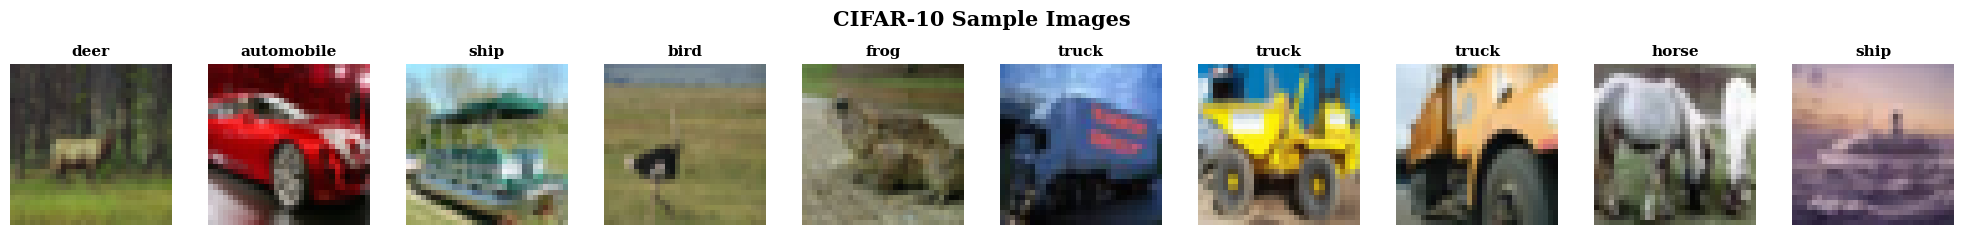

Saved: figures/03_sample_images.eps


In [12]:
"""
Display ten sample CIFAR-10 images with their class labels.
"""
def plot_sample_images(images, labels, class_names, n=10, name="03_sample_images"):
    """Show n randomly-chosen images from `images` in a single-row subplot grid."""
    rng = np.random.default_rng(CONFIG["seed"])
    idx = rng.choice(len(images), size=n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax, i in zip(axes, idx):
        ax.imshow(images[i])
        ax.set_title(class_names[labels[i]], fontsize=11)
        ax.axis("off")
    fig.suptitle("CIFAR-10 Sample Images")
    fig.tight_layout()
    save_figure(fig, name)


plot_sample_images(x_train_full, y_train_full, CLASS_NAMES)

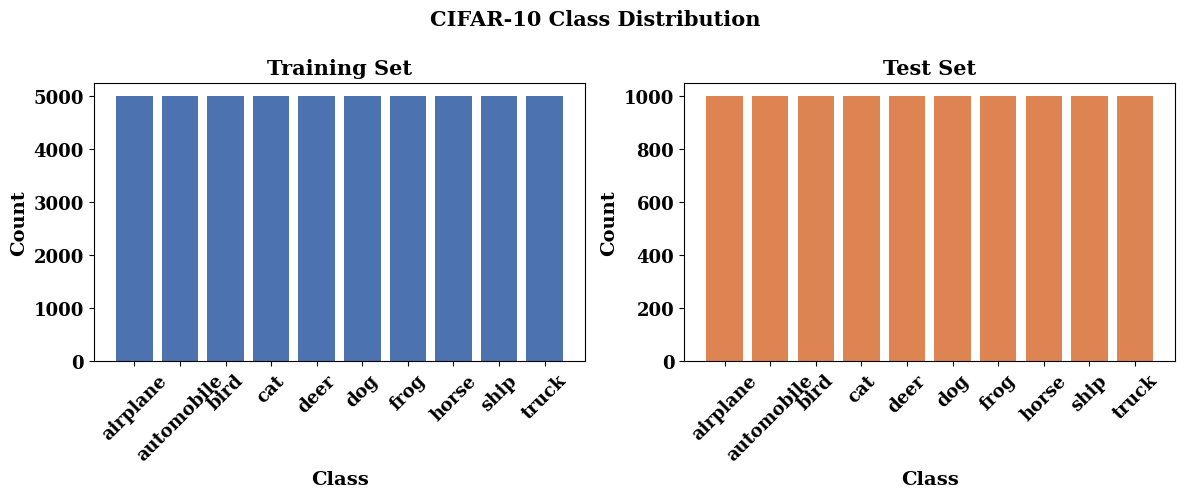

Saved: figures/04_class_distribution.eps


In [13]:
"""
Plot the class distribution for the training and test splits, clubbed into
one figure with two subplots.
"""
def plot_class_distribution(y_train, y_test, class_names, name="04_class_distribution"):
    """Bar chart of per-class sample counts for the train and test sets."""
    train_counts = pd.Series(y_train).value_counts().sort_index()
    test_counts = pd.Series(y_test).value_counts().sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].bar(class_names, train_counts.values, color="#4C72B0")
    axes[0].set_title("Training Set")
    axes[0].set_xlabel("Class")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].bar(class_names, test_counts.values, color="#DD8452")
    axes[1].set_title("Test Set")
    axes[1].set_xlabel("Class")
    axes[1].set_ylabel("Count")
    axes[1].tick_params(axis="x", rotation=45)

    fig.suptitle("CIFAR-10 Class Distribution")
    fig.tight_layout()
    save_figure(fig, name)


plot_class_distribution(y_train_full, y_test, CLASS_NAMES)

In [14]:
"""
Normalize pixel values to [0, 1] and carve a validation split out of the
training set. The 10,000-image test set stays untouched until Task 7.
"""
x_train_full_norm = x_train_full.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

n_val = int(len(x_train_full_norm) * CONFIG["val_fraction"])
rng = np.random.default_rng(CONFIG["seed"])
perm = rng.permutation(len(x_train_full_norm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

x_train, y_train = x_train_full_norm[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full_norm[val_idx], y_train_full[val_idx]

print("Train:", x_train.shape, " Val:", x_val.shape, " Test:", x_test_norm.shape)

Train: (45000, 32, 32, 3)  Val: (5000, 32, 32, 3)  Test: (10000, 32, 32, 3)


## Part D — Task 2 & 3: Kernel-Size, Stride, and Padding Studies

**Task 2:** Implement a convolution layer and compare kernel sizes 3×3, 5×5, and 7×7;
record the resulting feature-map sizes.

In [15]:
"""
Task 2: Compare 3x3, 5x5, and 7x7 convolution kernels on a sample CIFAR-10
image and record the resulting feature-map sizes (valid padding, stride 1,
8 filters, random/untrained weights — the point here is spatial geometry,
not learned features).
"""
sample_batch = x_train[:1]  # single image, shape (1, 32, 32, 3)

kernel_sizes = [3, 5, 7]
size_records = []
kernel_size_feature_maps = {}

for ks in kernel_sizes:
    conv_layer = layers.Conv2D(filters=8, kernel_size=ks, strides=1, padding="valid")
    output = conv_layer(sample_batch)
    kernel_size_feature_maps[ks] = output.numpy()[0]
    formula_size = conv_output_size(n=32, f=ks, p=0, s=1)
    size_records.append({
        "Kernel Size": f"{ks}x{ks}",
        "Formula Output Size": formula_size,
        "Actual Output Shape": tuple(output.shape[1:3]),
    })

kernel_size_df = pd.DataFrame(size_records)
kernel_size_df

,Kernel Size,Formula Output Size,Actual Output Shape
0,3x3,30,"(30, 30)"
1,5x5,28,"(28, 28)"
2,7x7,26,"(26, 26)"


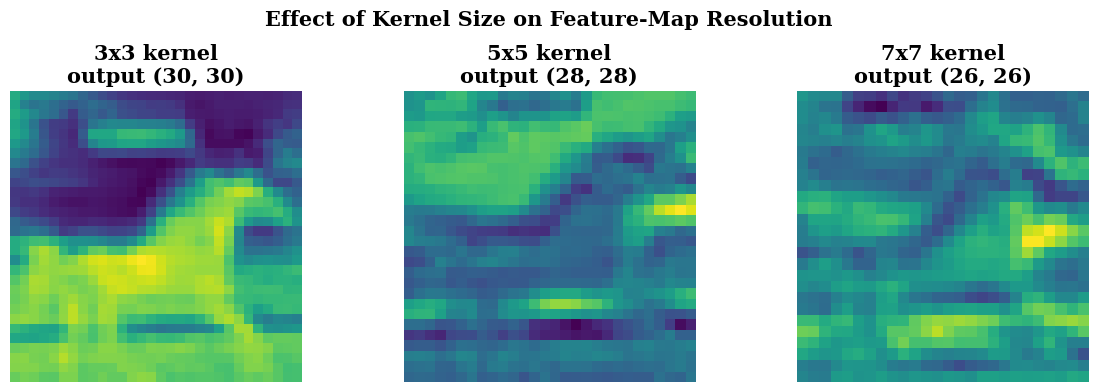

Saved: figures/05_kernel_size_feature_maps.eps


'figures/05_kernel_size_feature_maps.eps'

In [16]:
"""
Visualize one output feature-map channel for each kernel size, side by
side, to see how kernel size affects spatial resolution.
"""
fig, axes = plt.subplots(1, len(kernel_sizes), figsize=(4 * len(kernel_sizes), 4))
for ax, ks in zip(axes, kernel_sizes):
    fm_channel = kernel_size_feature_maps[ks][:, :, 0]
    ax.imshow(fm_channel, cmap="viridis")
    ax.set_title(f"{ks}x{ks} kernel\noutput {fm_channel.shape}")
    ax.axis("off")
fig.suptitle("Effect of Kernel Size on Feature-Map Resolution")
fig.tight_layout()
save_figure(fig, "05_kernel_size_feature_maps")

**Task 3:** Study stride ∈ {1, 2} and padding ∈ {same, valid}; compute the resulting
output dimensions.

In [17]:
"""
Task 3: Study how stride and padding affect output feature-map size, and
verify the Keras-computed shape against the closed-form formula.
"""
strides_to_test = [1, 2]
paddings_to_test = ["valid", "same"]
stride_padding_records = []

for pad in paddings_to_test:
    for stride in strides_to_test:
        conv_layer = layers.Conv2D(filters=8, kernel_size=3, strides=stride, padding=pad)
        output = conv_layer(sample_batch)
        if pad == "valid":
            formula_size = conv_output_size(n=32, f=3, p=0, s=stride)
        else:
            formula_size = int(np.ceil(32 / stride))  # 'same' padding target
        stride_padding_records.append({
            "Padding": pad,
            "Stride": stride,
            "Formula Output Size": formula_size,
            "Actual Output Shape": tuple(output.shape[1:3]),
        })

stride_padding_df = pd.DataFrame(stride_padding_records)
stride_padding_df

,Padding,Stride,Formula Output Size,Actual Output Shape
0,valid,1,30,"(30, 30)"
1,valid,2,15,"(15, 15)"
2,same,1,32,"(32, 32)"
3,same,2,16,"(16, 16)"


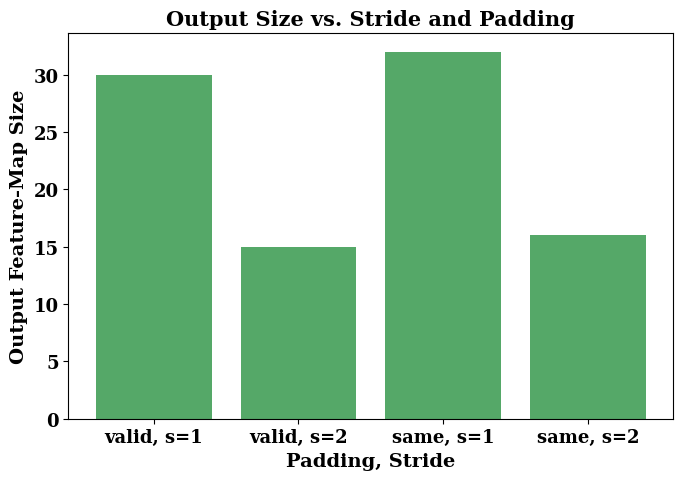

Saved: figures/06_stride_padding_comparison.eps


'figures/06_stride_padding_comparison.eps'

In [18]:
"""
Visualize output spatial size across the four stride/padding combinations.
"""
fig, ax = plt.subplots(figsize=(7, 5))
combo_labels = [f"{r['Padding']}, s={r['Stride']}" for r in stride_padding_records]
combo_sizes = [r["Actual Output Shape"][0] for r in stride_padding_records]
ax.bar(combo_labels, combo_sizes, color="#55A868")
ax.set_xlabel("Padding, Stride")
ax.set_ylabel("Output Feature-Map Size")
ax.set_title("Output Size vs. Stride and Padding")
fig.tight_layout()
save_figure(fig, "06_stride_padding_comparison")

## Part E — CNN Architecture Definition

A single modular builder function is used for the base Task 6 model and every
ablation-study variant (pooling type, activation function, filter count), so the
architecture logic is defined exactly once:

`Input -> [Conv -> Activation -> Pool] x N -> Flatten -> Dense -> Softmax`

In [19]:
"""
Modular CNN builder. All variants trained in this notebook (the Task 6
base model and every ablation-study variant) are instantiated through this
one function, keeping the architecture logic defined exactly once.
"""
def build_cnn(conv_filters=(32, 64), kernel_size=3, pooling="max", activation="relu",
              dense_units=128, num_classes=CONFIG["num_classes"],
              input_shape=CONFIG["img_shape"], learning_rate=CONFIG["learning_rate"]):
    """Build and compile Input -> [Conv -> Activation -> Pool] x N -> Flatten
    -> Dense -> Softmax, per the architecture specified in Task 6."""
    pool_layer_cls = layers.MaxPooling2D if pooling == "max" else layers.AveragePooling2D

    model = keras.Sequential(
        name=f"cnn_{pooling}pool_{activation}_{'-'.join(map(str, conv_filters))}f"
    )
    model.add(layers.Input(shape=input_shape))
    for i, n_filters in enumerate(conv_filters):
        model.add(layers.Conv2D(n_filters, kernel_size, padding="same", name=f"conv{i+1}"))
        model.add(layers.Activation(activation, name=f"act{i+1}"))
        model.add(pool_layer_cls(pool_size=2, name=f"pool{i+1}"))
    model.add(layers.Flatten())
    model.add(layers.Dense(dense_units, activation="relu", name="dense1"))
    model.add(layers.Dense(num_classes, activation="softmax", name="output"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


main_model = build_cnn()
main_model.summary()

Model: "cnn_maxpool_relu_32-64f"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act1 (Activation)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act2 (Activation)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
"""
Cross-check the first convolution layer's parameter count against the
closed-form formula.
"""
first_conv_params_formula = conv_param_count(num_filters=32, kernel_size=3, in_channels=3)
first_conv_params_actual = main_model.get_layer("conv1").count_params()
print("Formula:", first_conv_params_formula, " Keras:", first_conv_params_actual,
      " Match:", first_conv_params_formula == first_conv_params_actual)

Formula: 896  Keras: 896  Match: True


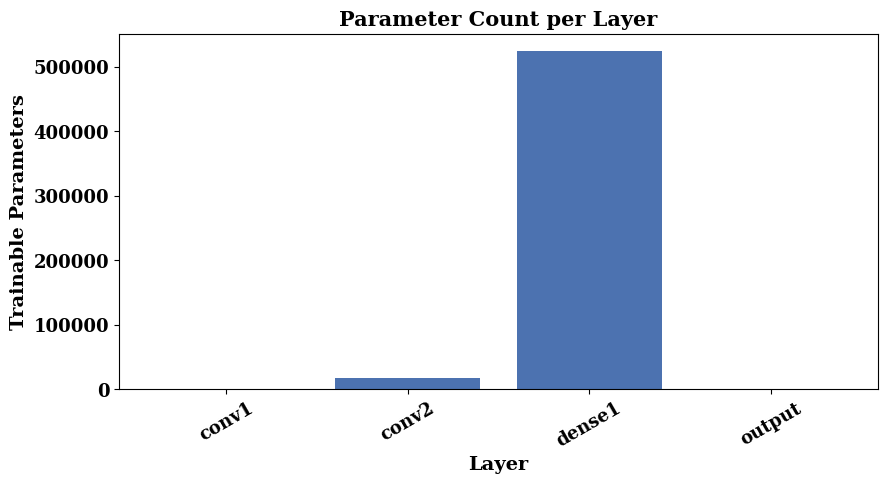

Saved: figures/04b_layer_parameter_breakdown.eps


In [21]:
"""
Per-layer trainable-parameter breakdown for the main model, as a
visualization of where parameters concentrate across the network (relevant
to the discussion question on CNNs vs. MLPs' parameter counts).
"""
def plot_layer_param_breakdown(model, name="04b_layer_parameter_breakdown"):
    """Bar chart of trainable-parameter count for every layer that has
    weights."""
    layer_names, layer_params = [], []
    for layer in model.layers:
        n = layer.count_params()
        if n > 0:
            layer_names.append(layer.name)
            layer_params.append(n)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(layer_names, layer_params, color="#4C72B0")
    ax.set_xlabel("Layer")
    ax.set_ylabel("Trainable Parameters")
    ax.set_title("Parameter Count per Layer")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    save_figure(fig, name)


plot_layer_param_breakdown(main_model)

## Part F — Task 4: Feature-Map and Filter Visualization (Untrained)

Visualize the feature maps produced by the first convolution layer. Shown here on the
freshly-initialized (untrained) `main_model` to isolate the effect of the architecture
itself; the same visualization is repeated after training in Part M for comparison.

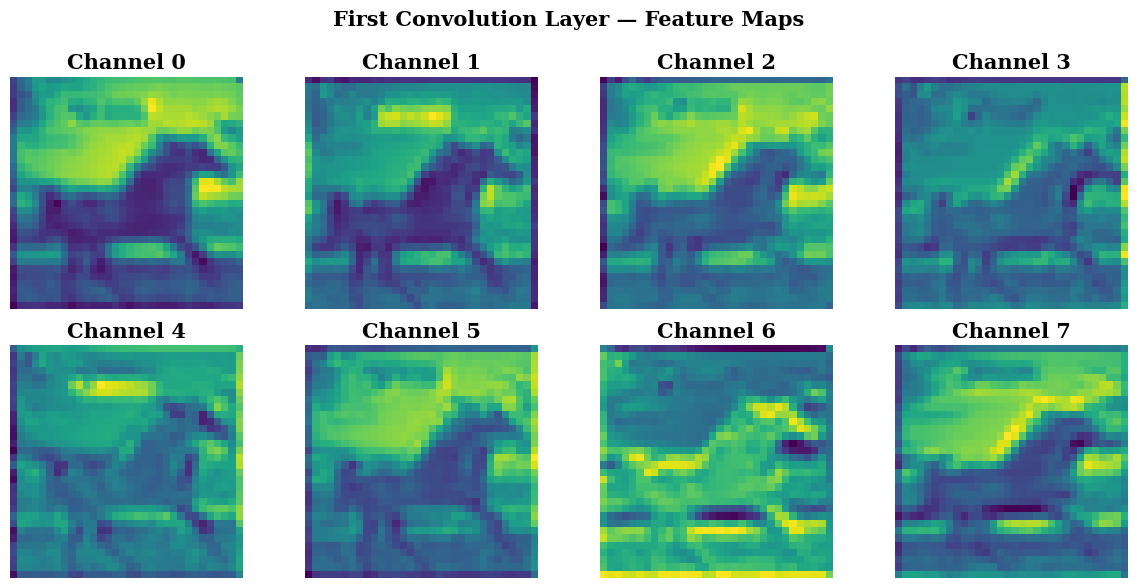

Saved: figures/07_feature_maps_untrained.eps


In [26]:
"""
Task 4: Build a sub-model that exposes the first convolution layer's
activations, and a generic plotting helper reused for both the untrained
and (later) trained versions of the model.
"""
def get_feature_map_extractor(model, layer_name, input_shape=CONFIG["img_shape"]):
    """Return a Keras Model exposing the output of `layer_name`, built by
    replaying `model`'s layers on a fresh Input tensor. This reuses the
    original layers' weights (no retraining, non-destructive) and sidesteps
    Keras 3's `.input`/`.output` property issues on Sequential models."""
    new_input = keras.Input(shape=input_shape)
    x = new_input
    target_output = None
    for layer in model.layers:
        x = layer(x)
        if layer.name == layer_name:
            target_output = x
    if target_output is None:
        raise ValueError(f"Layer '{layer_name}' not found in model.")
    return keras.Model(inputs=new_input, outputs=target_output)


def plot_feature_maps(extractor, image_batch, n_maps=8, name="feature_maps"):
    """Run `image_batch` (1, H, W, C) through `extractor` and display the
    first n_maps output channels in a subplot grid."""
    activations = extractor(image_batch).numpy()[0]  # (H, W, C)
    n_maps = min(n_maps, activations.shape[-1])
    n_cols = 4
    n_rows = int(np.ceil(n_maps / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
    axes = np.array(axes).flatten()
    for i in range(n_maps):
        axes[i].imshow(activations[:, :, i], cmap="viridis")
        axes[i].set_title(f"Channel {i}")
        axes[i].axis("off")
    for j in range(n_maps, len(axes)):
        axes[j].axis("off")
    fig.suptitle("First Convolution Layer — Feature Maps")
    fig.tight_layout()
    save_figure(fig, name)


sample_image_batch = x_train[:1]
untrained_extractor = get_feature_map_extractor(main_model, "conv1")
plot_feature_maps(untrained_extractor, sample_image_batch, n_maps=8, name="07_feature_maps_untrained")

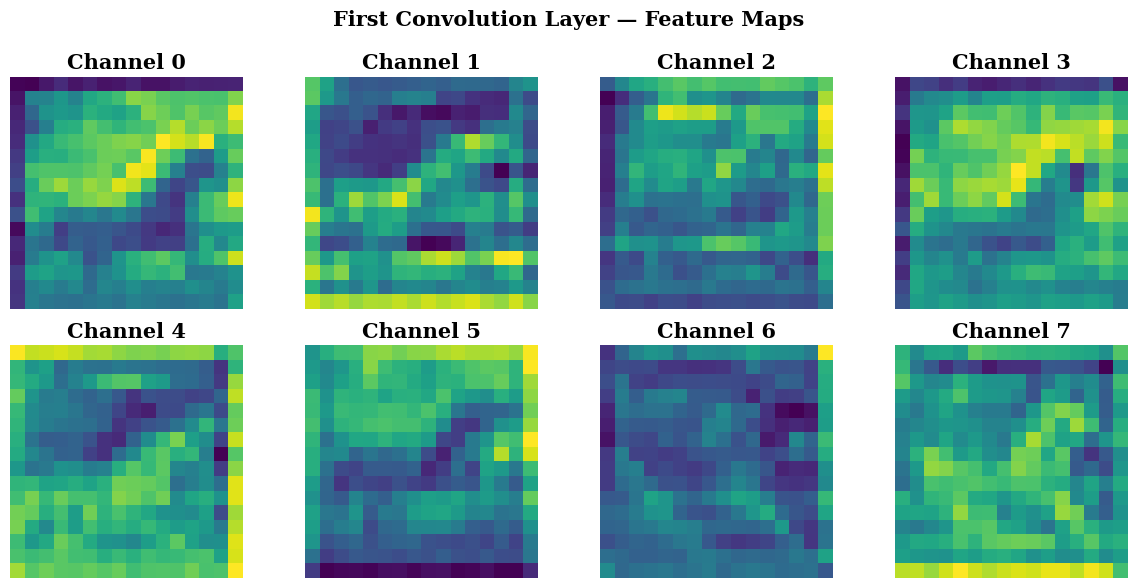

Saved: figures/07b_feature_maps_conv2_untrained.eps


In [27]:
"""
Hierarchical feature learning: repeat the extraction on the second
convolution layer (conv2) so the first- and second-layer feature maps can
be compared side by side (Part M repeats this after training).
"""
untrained_extractor_conv2 = get_feature_map_extractor(main_model, "conv2")
plot_feature_maps(untrained_extractor_conv2, sample_image_batch, n_maps=8,
                   name="07b_feature_maps_conv2_untrained")

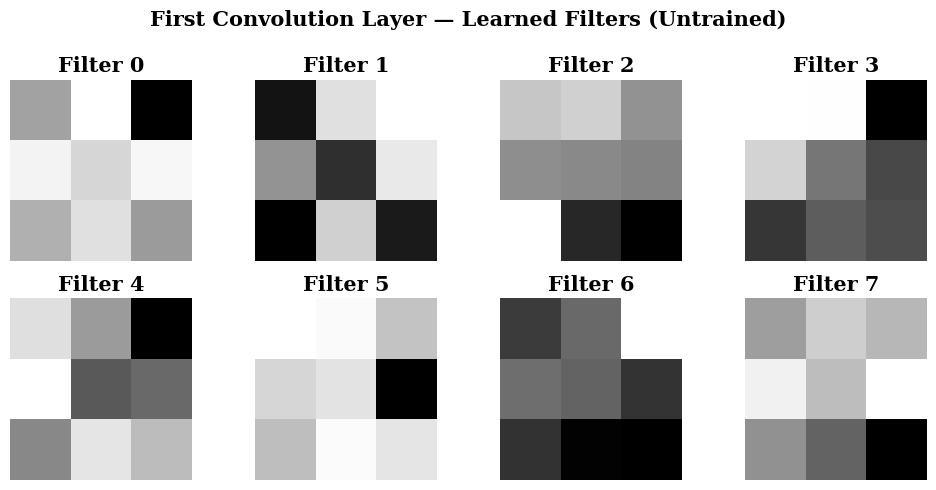

Saved: figures/08_conv1_filters.eps


In [28]:
"""
Bonus visualization: the raw learned weights of the first convolution
layer's kernels themselves (as opposed to their output feature maps),
directly comparable to the classical kernels explored in Part A.
"""
def plot_conv1_filters(model, layer_name="conv1", n_filters=8, name="08_conv1_filters"):
    """Display the first n_filters kernels of `layer_name`, averaged across
    input channels for a single-channel visualization."""
    weights = model.get_layer(layer_name).get_weights()[0]  # (kh, kw, in_c, out_c)
    n_filters = min(n_filters, weights.shape[-1])
    n_cols = 4
    n_rows = int(np.ceil(n_filters / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols, 2.5 * n_rows))
    axes = np.array(axes).flatten()
    for i in range(n_filters):
        kernel_img = weights[:, :, :, i].mean(axis=-1)
        axes[i].imshow(kernel_img, cmap="gray")
        axes[i].set_title(f"Filter {i}")
        axes[i].axis("off")
    for j in range(n_filters, len(axes)):
        axes[j].axis("off")
    fig.suptitle("First Convolution Layer — Learned Filters (Untrained)")
    fig.tight_layout()
    save_figure(fig, name)


plot_conv1_filters(main_model)

## Part G — Shared Training/Evaluation Harness

Training logic is written once and reused for the Task 6 base model and every
ablation-study variant that follows.

In [29]:
"""
Shared training/evaluation harness. Trains a model, times the run, and
evaluates on the held-out test set.
"""
results = {}  # collects every trained variant's results for the final summary table


def train_and_evaluate(model, x_train, y_train, x_val, y_val, x_test, y_test,
                        epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"]):
    """Train `model`, time the run, and evaluate on the test set. Returns a
    dict with the Keras History, test loss/accuracy, wall-clock training
    time in seconds, and parameter count."""
    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
    )
    elapsed = time.time() - start
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    return {
        "model": model,
        "history": history.history,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "train_time_sec": elapsed,
        "n_params": model.count_params(),
    }


def plot_learning_curves(history, name):
    """Club training/validation accuracy and loss into one 1x2 figure
    (mandatory plots: training accuracy, validation accuracy, training loss,
    validation loss)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(history["accuracy"], label="Train", marker="o", markersize=3)
    axes[0].plot(history["val_accuracy"], label="Validation", marker="s", markersize=3)
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title("Accuracy")
    axes[0].legend()

    axes[1].plot(history["loss"], label="Train", marker="o", markersize=3)
    axes[1].plot(history["val_loss"], label="Validation", marker="s", markersize=3)
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].set_title("Loss")
    axes[1].legend()

    fig.suptitle("Training and Validation Curves")
    fig.tight_layout()
    save_figure(fig, name)


def plot_variant_comparison(results_dict, keys, title, name):
    """Overlay validation-accuracy curves and a test-accuracy bar chart for
    the given variant keys of `results_dict`, clubbed into one figure."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
    for k in keys:
        axes[0].plot(results_dict[k]["history"]["val_accuracy"], label=k, marker="o", markersize=3)
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Validation Accuracy")
    axes[0].set_title("Validation Accuracy Curves")
    axes[0].legend()

    test_accs = [results_dict[k]["test_accuracy"] for k in keys]
    axes[1].bar(keys, test_accs, color=palette[:len(keys)])
    axes[1].set_xlabel("Variant")
    axes[1].set_ylabel("Test Accuracy")
    axes[1].set_title("Final Test Accuracy")
    axes[1].tick_params(axis="x", rotation=15)

    fig.suptitle(title)
    fig.tight_layout()
    save_figure(fig, name)

## Part H — Task 6: Main CNN Training

`Input -> Conv -> ReLU -> MaxPool -> Conv -> ReLU -> MaxPool -> Flatten -> Dense ->
Softmax`, trained with the Adam optimizer for 20 epochs at batch size 32.

In [30]:
"""
Task 6: Train the main CNN.
"""
results["main (MaxPool, ReLU, 32-64f)"] = train_and_evaluate(
    main_model, x_train, y_train, x_val, y_val, x_test_norm, y_test
)

main_key = "main (MaxPool, ReLU, 32-64f)"
print(f"Test accuracy: {results[main_key]['test_accuracy']:.4f}")
print(f"Training time: {results[main_key]['train_time_sec']:.1f}s")

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.4945 - loss: 1.4062 - val_accuracy: 0.5638 - val_loss: 1.1937
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6315 - loss: 1.0376 - val_accuracy: 0.6442 - val_loss: 1.0141
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6908 - loss: 0.8791 - val_accuracy: 0.6654 - val_loss: 0.9421
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7301 - loss: 0.7717 - val_accuracy: 0.6770 - val_loss: 0.9205
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7628 - loss: 0.6799 - val_accuracy: 0.6674 - val_loss: 0.9751
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7921 - loss: 0.6001 - val_accuracy: 0.6552 - val_loss: 1.0607
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8205 - loss: 0.5237 - val_accuracy: 0.6384 - val_loss: 1.2276
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8431 - loss: 0.4567 -

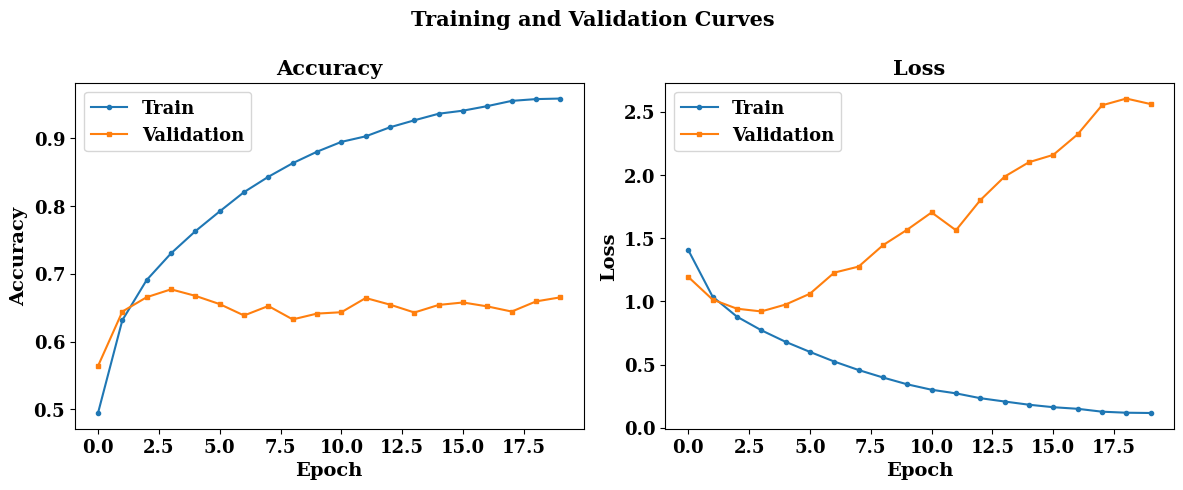

Saved: figures/09_main_model_learning_curves.eps


In [31]:
plot_learning_curves(results[main_key]["history"], "09_main_model_learning_curves")

## Part I — Task 5: Max-Pooling vs. Average-Pooling

The main model above already uses Max Pooling, so only the Average Pooling variant
needs a fresh training run.

In [32]:
"""
Task 5: Compare Max Pooling vs. Average Pooling (same architecture and
hyperparameters otherwise).
"""
avgpool_model = build_cnn(pooling="avg")
results["avg-pool variant"] = train_and_evaluate(
    avgpool_model, x_train, y_train, x_val, y_val, x_test_norm, y_test
)

print(f"Test accuracy: {results['avg-pool variant']['test_accuracy']:.4f}")

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4710 - loss: 1.4755 - val_accuracy: 0.5320 - val_loss: 1.3195
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5953 - loss: 1.1468 - val_accuracy: 0.5908 - val_loss: 1.1302
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6480 - loss: 1.0012 - val_accuracy: 0.6204 - val_loss: 1.0640
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6852 - loss: 0.9032 - val_accuracy: 0.6340 - val_loss: 1.0230
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7114 - loss: 0.8253 - val_accuracy: 0.6458 - val_loss: 0.9993
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7362 - loss: 0.7558 - val_accuracy: 0.6534 - val_loss: 0.9982
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7590 - loss: 0.6935 - val_accuracy: 0.6544 - val_loss: 1.0116
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7800 - loss: 0.6336 -

In [34]:
"""
Verify that Max- and Average-Pooling produce identical output *spatial*
sizes for the same pool size and stride (only the pooled values differ),
per Task 5's "compare output size" requirement.
"""
pool_formula_size = conv_output_size(n=32, f=2, p=0, s=2)
print("Pooling output size (formula, per stage):", pool_formula_size)
print("Max-pool variant pool1 output shape:", main_model.get_layer("pool1").output.shape)
print("Avg-pool variant pool1 output shape:", avgpool_model.get_layer("pool1").output.shape)

Pooling output size (formula, per stage): 16
Max-pool variant pool1 output shape: (None, 16, 16, 32)
Avg-pool variant pool1 output shape: (None, 16, 16, 32)


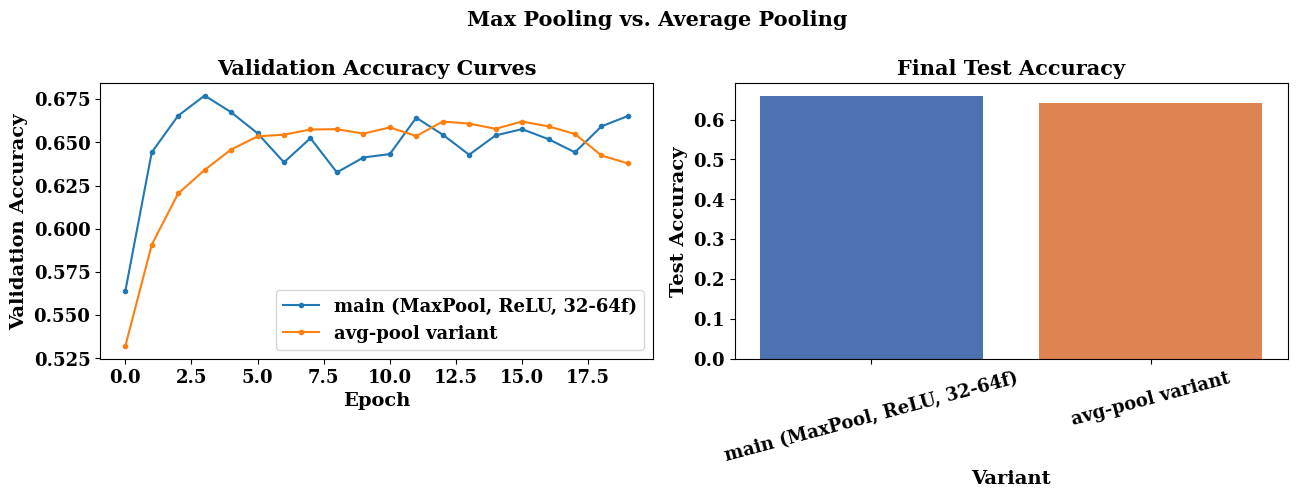

Saved: figures/10_pooling_comparison.eps


In [35]:
plot_variant_comparison(
    results, [main_key, "avg-pool variant"],
    "Max Pooling vs. Average Pooling", "10_pooling_comparison"
)

## Part J — Additional Exercise 3: ReLU vs. Sigmoid Activation

The main model already uses ReLU, so only the Sigmoid variant needs a fresh run.

In [36]:
"""
Additional Exercise 3: Compare ReLU vs. Sigmoid activation.
"""
sigmoid_model = build_cnn(activation="sigmoid")
results["sigmoid variant"] = train_and_evaluate(
    sigmoid_model, x_train, y_train, x_val, y_val, x_test_norm, y_test
)

print(f"Test accuracy: {results['sigmoid variant']['test_accuracy']:.4f}")

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.1000 - loss: 2.3069 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0946 - val_loss: 2.3031
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.0988 - loss: 2.3028 

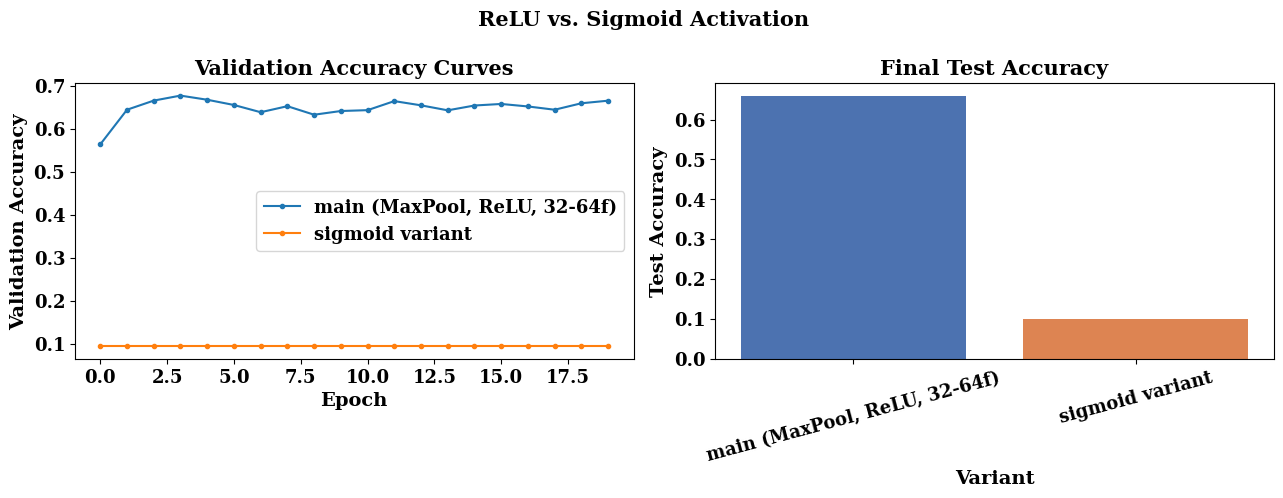

Saved: figures/11_activation_comparison.eps


In [37]:
plot_variant_comparison(
    results, [main_key, "sigmoid variant"],
    "ReLU vs. Sigmoid Activation", "11_activation_comparison"
)

## Part K — Additional Exercise 5: 16 vs. 64 Convolution Filters

Two fresh models with symmetric filter counts (16-16 and 64-64) across both
convolution layers, all else identical, comparing both accuracy and computation time.

In [38]:
"""
Additional Exercise 5: Compare 16 vs. 64 convolution filters, and analyze
the effect on both accuracy and training time.
"""
filters16_model = build_cnn(conv_filters=(16, 16))
results["16-filter variant"] = train_and_evaluate(
    filters16_model, x_train, y_train, x_val, y_val, x_test_norm, y_test
)

filters64_model = build_cnn(conv_filters=(64, 64))
results["64-filter variant"] = train_and_evaluate(
    filters64_model, x_train, y_train, x_val, y_val, x_test_norm, y_test
)

for k in ["16-filter variant", "64-filter variant"]:
    print(f"{k}: acc={results[k]['test_accuracy']:.4f}, "
          f"time={results[k]['train_time_sec']:.1f}s, params={results[k]['n_params']}")

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.4722 - loss: 1.4807 - val_accuracy: 0.5164 - val_loss: 1.3420
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5819 - loss: 1.1820 - val_accuracy: 0.5706 - val_loss: 1.2017
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6315 - loss: 1.0501 - val_accuracy: 0.6012 - val_loss: 1.1322
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6644 - loss: 0.9604 - val_accuracy: 0.6200 - val_loss: 1.0847
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6890 - loss: 0.8908 - val_accuracy: 0.6244 - val_loss: 1.0792
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7079 - loss: 0.8302 - val_accuracy: 0.6336 - val_loss: 1.0667
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7280 - loss: 0.7758 - val_accuracy: 0.6320 - val_loss: 1.0964
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7450 - loss: 0.7280 

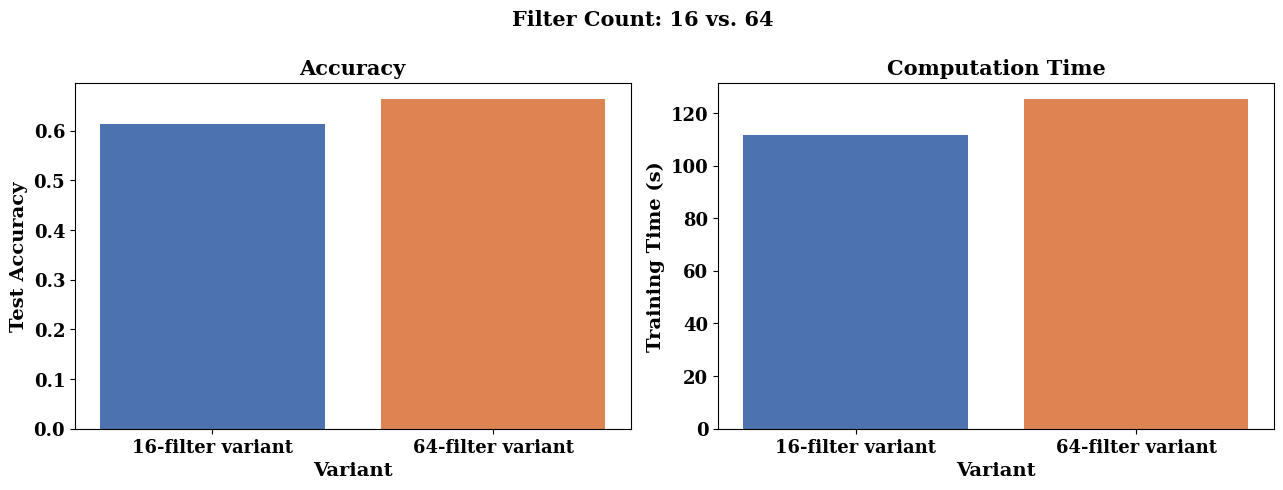

Saved: figures/12_filter_count_comparison.eps


'figures/12_filter_count_comparison.eps'

In [39]:
"""
Compare the 16- vs. 64-filter variants on both test accuracy and wall-clock
training time, clubbed into one figure.
"""
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
filter_keys = ["16-filter variant", "64-filter variant"]
palette = ["#4C72B0", "#DD8452"]

accs = [results[k]["test_accuracy"] for k in filter_keys]
times = [results[k]["train_time_sec"] for k in filter_keys]

axes[0].bar(filter_keys, accs, color=palette)
axes[0].set_xlabel("Variant")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Accuracy")

axes[1].bar(filter_keys, times, color=palette)
axes[1].set_xlabel("Variant")
axes[1].set_ylabel("Training Time (s)")
axes[1].set_title("Computation Time")

fig.suptitle("Filter Count: 16 vs. 64")
fig.tight_layout()
save_figure(fig, "12_filter_count_comparison")

## Part L — Additional Exercises 1, 2, and 4

In [40]:
"""
Additional Exercise 1: Output size for a 64x64 image, 5x5 kernel,
stride 2, padding 2.
"""
ex1_output = conv_output_size(n=64, f=5, p=2, s=2)
print(f"Output size = {ex1_output} x {ex1_output}")

Output size = 32 x 32


In [41]:
"""
Additional Exercise 2: Trainable parameters for a convolution layer with
64 filters of size 3x3 on an RGB input.
"""
ex2_params = conv_param_count(num_filters=64, kernel_size=3, in_channels=3)
print(f"Trainable parameters = {ex2_params}")

Trainable parameters = 1792


**Additional Exercise 4 — Average Pooling Comparison:** this is the same comparison
already carried out in Task 5 above (Max Pooling vs. Average Pooling) — see the
results and plot in Part I rather than re-training an identical model.

## Part M — Task 7: Full Evaluation of the Main Model

Accuracy, precision, recall, F1-score, confusion matrix, and classification report for
the Task 6 main model, plus the trained-model counterparts of the Task 4 feature-map
and filter visualizations.

In [42]:
"""
Task 7: Predict on the test set and compute headline classification
metrics for the main Task 6 model.
"""
eval_model = results[main_key]["model"]
y_pred_probs = eval_model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

report_dict = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df

Accuracy:  0.6584
Precision: 0.6611
Recall:    0.6584
F1-score:  0.6582


,precision,recall,f1-score,support
airplane,0.687438,0.6950,0.691198,1000.0000
automobile,0.766310,0.7870,0.776517,1000.0000
bird,0.615000,0.4920,0.546667,1000.0000
cat,0.437132,0.4450,0.441031,1000.0000
deer,0.648087,0.5930,0.619321,1000.0000
dog,0.488665,0.5820,0.531264,1000.0000
frog,0.752443,0.6930,0.721499,1000.0000
horse,0.706161,0.7450,0.725061,1000.0000
ship,0.795918,0.7800,0.787879,1000.0000
truck,0.713494,0.7720,0.741595,1000.0000


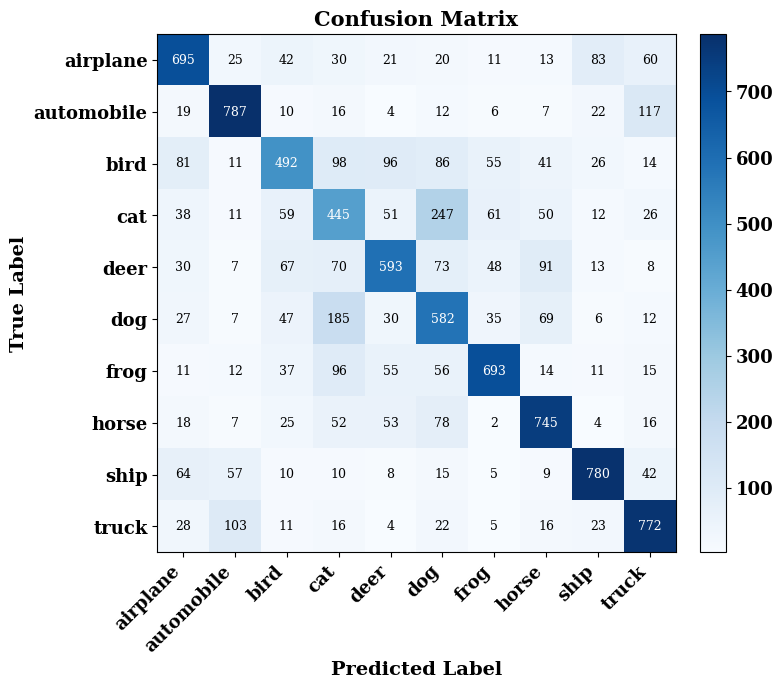

Saved: figures/13_confusion_matrix.eps


In [43]:
"""
Confusion matrix heatmap.
"""
def plot_confusion_matrix(y_true, y_pred, class_names, name="13_confusion_matrix"):
    """Render an annotated confusion-matrix heatmap."""
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_title("Confusion Matrix")
    threshold = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > threshold else "black", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    save_figure(fig, name)


plot_confusion_matrix(y_test, y_pred, CLASS_NAMES)

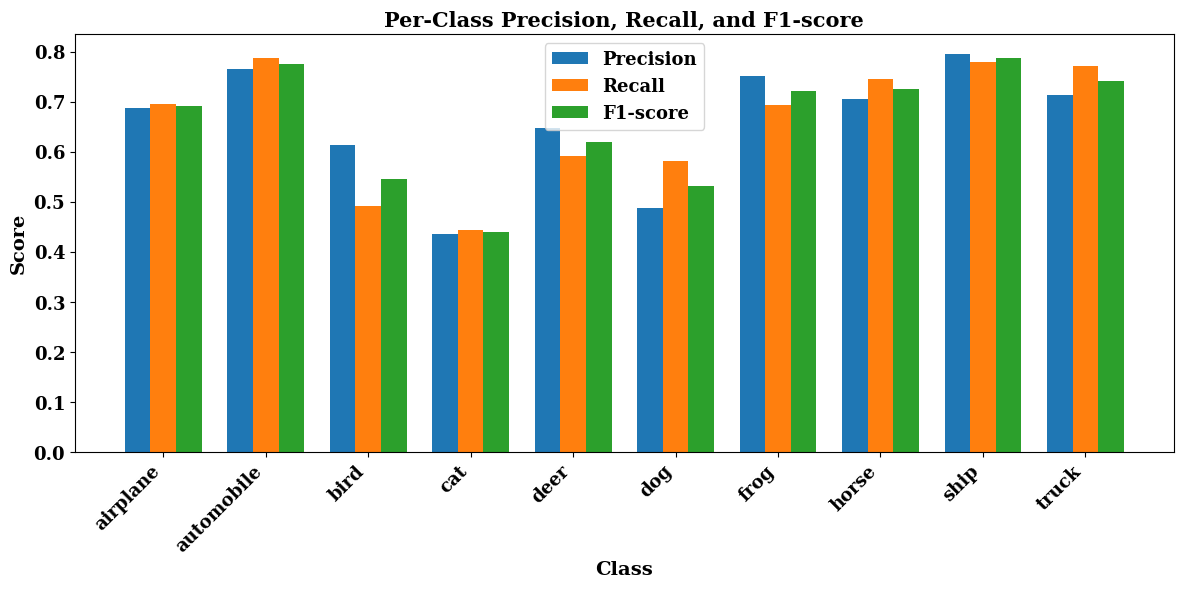

Saved: figures/14_per_class_metrics.eps


In [44]:
"""
Bonus visualization: per-class precision, recall, and F1-score.
"""
def plot_per_class_metrics(report_df, class_names, name="14_per_class_metrics"):
    """Grouped bar chart of precision/recall/F1 for each class."""
    metrics_df = report_df.loc[class_names, ["precision", "recall", "f1-score"]]
    x = np.arange(len(class_names))
    width = 0.25
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width, metrics_df["precision"], width, label="Precision")
    ax.bar(x, metrics_df["recall"], width, label="Recall")
    ax.bar(x + width, metrics_df["f1-score"], width, label="F1-score")
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_xlabel("Class")
    ax.set_ylabel("Score")
    ax.set_title("Per-Class Precision, Recall, and F1-score")
    ax.legend()
    fig.tight_layout()
    save_figure(fig, name)


plot_per_class_metrics(report_df, CLASS_NAMES)

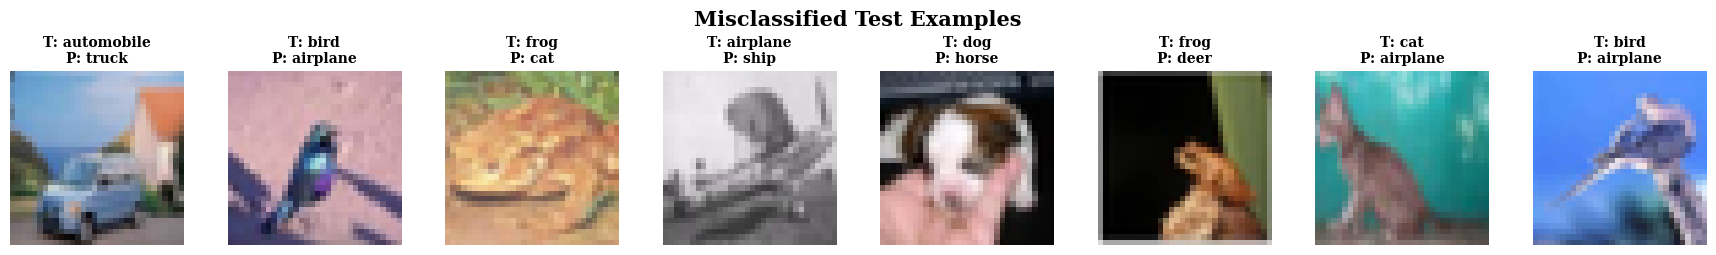

Saved: figures/15_misclassified_examples.eps


In [45]:
"""
Bonus visualization: a sample of misclassified test images with their true
and predicted labels.
"""
def plot_misclassified(x, y_true, y_pred, class_names, n=8, name="15_misclassified_examples"):
    """Display up to n images where the prediction differs from the true label."""
    wrong_idx = np.where(y_true != y_pred)[0]
    n = min(n, len(wrong_idx))
    chosen = np.random.default_rng(CONFIG["seed"]).choice(wrong_idx, size=n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for ax, i in zip(axes, chosen):
        ax.imshow(x[i])
        ax.set_title(f"T: {class_names[y_true[i]]}\nP: {class_names[y_pred[i]]}", fontsize=10)
        ax.axis("off")
    fig.suptitle("Misclassified Test Examples")
    fig.tight_layout()
    save_figure(fig, name)


plot_misclassified(x_test, y_test, y_pred, CLASS_NAMES)

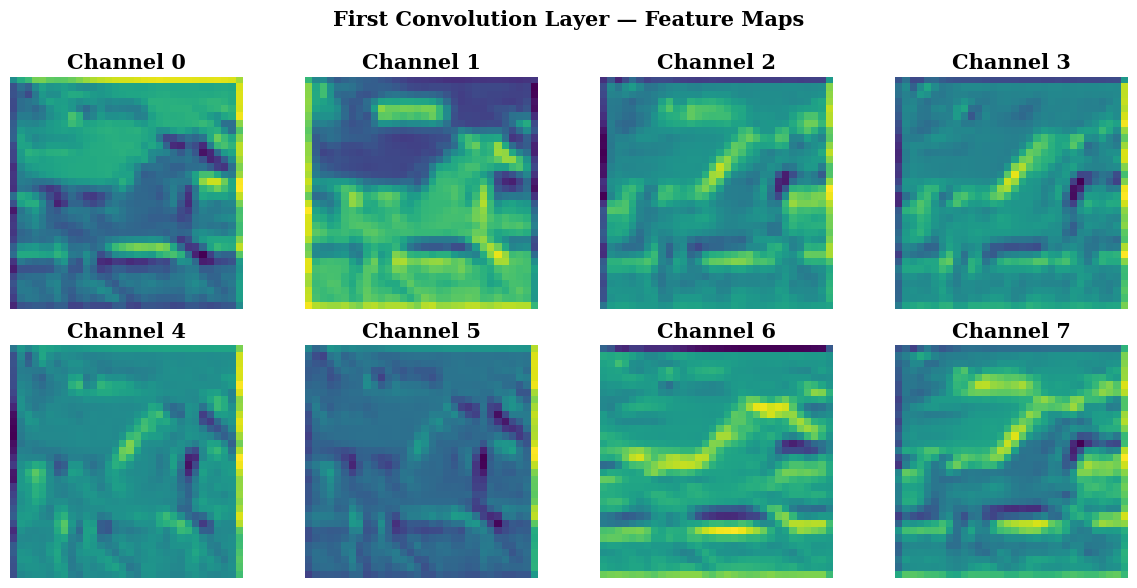

Saved: figures/16_feature_maps_trained.eps


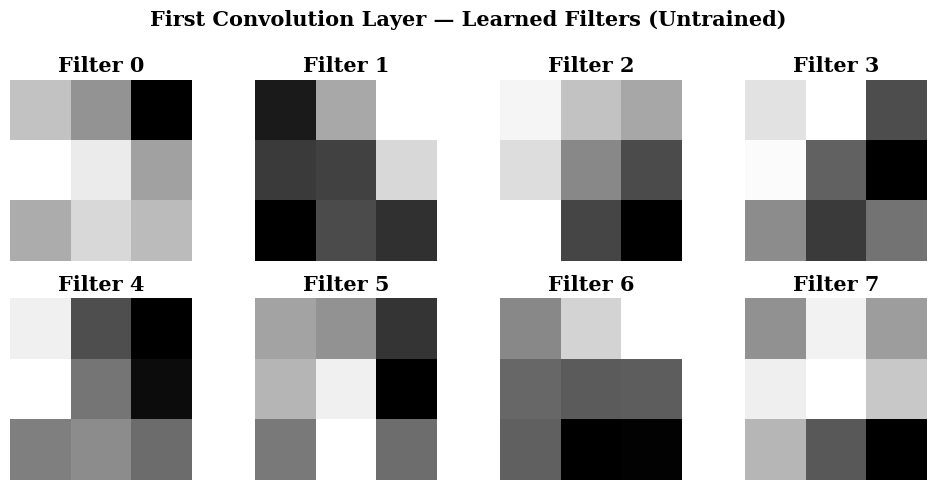

Saved: figures/17_conv1_filters_trained.eps


In [46]:
"""
Bonus: repeat the Task 4 feature-map and filter visualization on the
now-trained model, for direct comparison against the untrained versions in
Part F.
"""
trained_extractor = get_feature_map_extractor(eval_model, "conv1")
plot_feature_maps(trained_extractor, sample_image_batch, n_maps=8, name="16_feature_maps_trained")
plot_conv1_filters(eval_model, name="17_conv1_filters_trained")

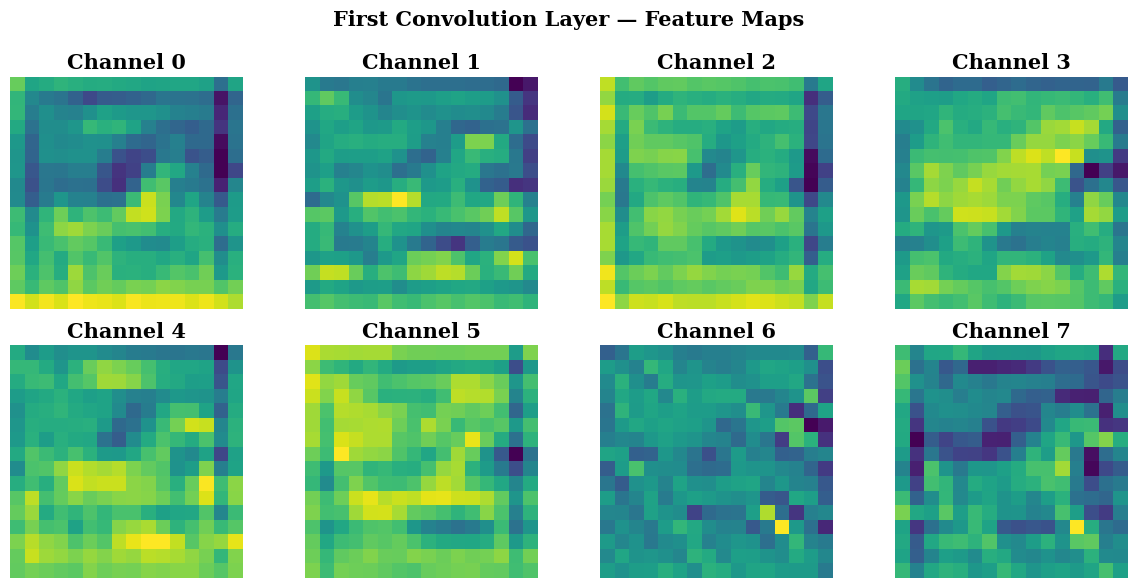

Saved: figures/17b_feature_maps_conv2_trained.eps


In [47]:
"""
Trained-model conv2 feature maps, for direct comparison against the
trained conv1 maps above and the untrained conv1/conv2 maps in Part F —
together these four views make the layer-wise progression from low-level
edges to more abstract, spatially-coarser patterns observable.
"""
trained_extractor_conv2 = get_feature_map_extractor(eval_model, "conv2")
plot_feature_maps(trained_extractor_conv2, sample_image_batch, n_maps=8,
                   name="17b_feature_maps_conv2_trained")

## Part N — Results Summary and Model Export

Consolidated metrics across the main model and every ablation variant (Manual Section
11), plus persistence of results and trained models to disk.

In [48]:
"""
Compute weighted precision, recall, and F1-score for every trained variant,
for a complete final comparison table (cheap: inference only, no retraining).
"""
def compute_test_metrics(model, x_test, y_test):
    """Return weighted precision, recall, and F1-score for `model` on the test set."""
    preds = np.argmax(model.predict(x_test, verbose=0), axis=1)
    p, r, f, _ = precision_recall_fscore_support(y_test, preds, average="weighted")
    return p, r, f


for name, r in results.items():
    p, rec, f = compute_test_metrics(r["model"], x_test_norm, y_test)
    r["precision"], r["recall"], r["f1"] = p, rec, f

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [49]:
"""
Consolidated results table across the main model and every ablation
variant.
"""
summary_rows = []
for name, r in results.items():
    summary_rows.append({
        "Model": name,
        "Final Train Acc": round(r["history"]["accuracy"][-1], 4),
        "Final Val Acc": round(r["history"]["val_accuracy"][-1], 4),
        "Test Accuracy": round(r["test_accuracy"], 4),
        "Precision": round(r["precision"], 4),
        "Recall": round(r["recall"], 4),
        "F1-score": round(r["f1"], 4),
        "Train Time (s)": round(r["train_time_sec"], 1),
        "Parameters": r["n_params"],
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Model,Final Train Acc,Final Val Acc,Test Accuracy,Precision,Recall,F1-score,Train Time (s),Parameters
0,"main (MaxPool, ReLU, 32-64f)",0.9586,0.6652,0.6584,0.6611,0.6584,0.6582,123.8,545098
1,avg-pool variant,0.9310,0.6378,0.6411,0.6532,0.6411,0.6433,114.9,545098
2,sigmoid variant,0.0988,0.0946,0.1000,0.0100,0.1000,0.0182,133.5,545098
3,16-filter variant,0.8767,0.6198,0.6145,0.6093,0.6145,0.6096,111.6,135258
4,64-filter variant,0.9692,0.6480,0.6633,0.6740,0.6633,0.6651,125.2,564426


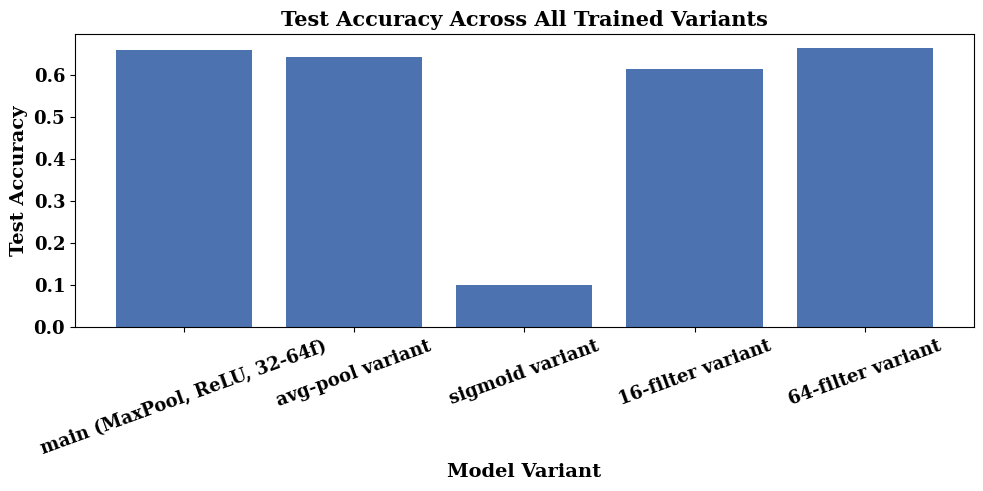

Saved: figures/18_all_variants_test_accuracy.eps


'figures/18_all_variants_test_accuracy.eps'

In [50]:
"""
Closing visualization: test accuracy across every trained variant in the
notebook (main architecture and every ablation), in one chart.
"""
fig, ax = plt.subplots(figsize=(10, 5))
variant_names = summary_df["Model"]
variant_accs = summary_df["Test Accuracy"]
ax.bar(variant_names, variant_accs, color="#4C72B0")
ax.set_xlabel("Model Variant")
ax.set_ylabel("Test Accuracy")
ax.set_title("Test Accuracy Across All Trained Variants")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_figure(fig, "18_all_variants_test_accuracy")

In [51]:
"""
Persist the results summary and trained models to disk.
"""
summary_df.to_csv(os.path.join(CONFIG["model_dir"], "results_summary.csv"), index=False)

for name, r in results.items():
    safe_name = (
        name.replace(" ", "_").replace("(", "").replace(")", "").replace(",", "")
    )
    r["model"].save(os.path.join(CONFIG["model_dir"], f"{safe_name}.keras"))

print("Saved results_summary.csv and all trained models to:", CONFIG["model_dir"])

Saved results_summary.csv and all trained models to: models
